In [1]:
import numpy as np
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from common.helper import *
import matplotlib.pyplot as plt
from mini_shap.independent_tree_shap import IndependentTreeExplainer
import pandas as pd
from tree.xg_classifier import XGClassifier
from xgboost import XGBClassifier
import shap

/home/sakane/Documents/projects/python/mini_xgshap/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
X_train, X_test, y_train, y_test, scale_pos_weight = load_data_and_scale_pos_weight(cast_string=True)
X_train_np, X_test_np, y_train_np, y_test_np = X_train.to_numpy().astype(np.float32), X_test.to_numpy().astype(np.float32), y_train.to_numpy().astype(np.float32), y_test.to_numpy().astype(np.float32)

In [3]:
m1 = XGBClassifier()
m1.load_model('../model/prauc_model2.ubj')
m2 = XGClassifier.load_from_xgbclassifier(m1, columns=list(X_train.columns))

In [4]:
pred_raw1 = m1.predict(X_test, output_margin=True)
pred_proba1 = m1.predict_proba(X_test)
y_pred = m1.predict(X_test)

In [5]:
expv, sv = load_shap_values("shap_values.npy")

In [6]:
mask = np.isclose(pred_raw1, expv + sv.sum(1), rtol=0.0, atol=1e-4)
mask.sum() == len(pred_raw1)

np.True_

In [7]:
explanation = shap.Explanation(
    values=sv,
    base_values=expv,
    data=X_test_np,
    feature_names=X_train.columns,
)

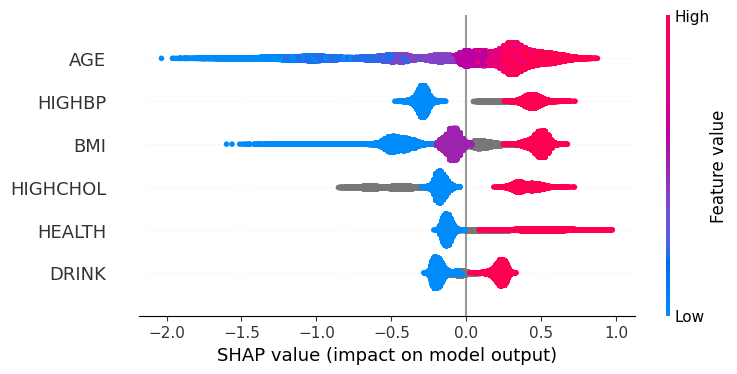

In [8]:
shap.plots.beeswarm(explanation, 
                order=explanation.abs.mean(0),
                max_display=6,
                group_remaining_features=False
            )

In [9]:
# shap.plots.beeswarm(explanation, order=explanation.abs.max(0), max_display=33)

In [10]:
X_test_replace_missing = X_test_np.copy()
X_test_replace_missing[np.isnan(X_test_replace_missing)] = -1

X_test_replace_missing

array([[0., 2., 1., ..., 0., 1., 0.],
       [0., 4., 1., ..., 0., 1., 0.],
       [1., 4., 0., ..., 0., 1., 1.],
       ...,
       [0., 4., 0., ..., 0., 0., 1.],
       [0., 4., 1., ..., 0., 1., 0.],
       [0., 1., 1., ..., 0., 1., 0.]], shape=(347338, 32), dtype=float32)

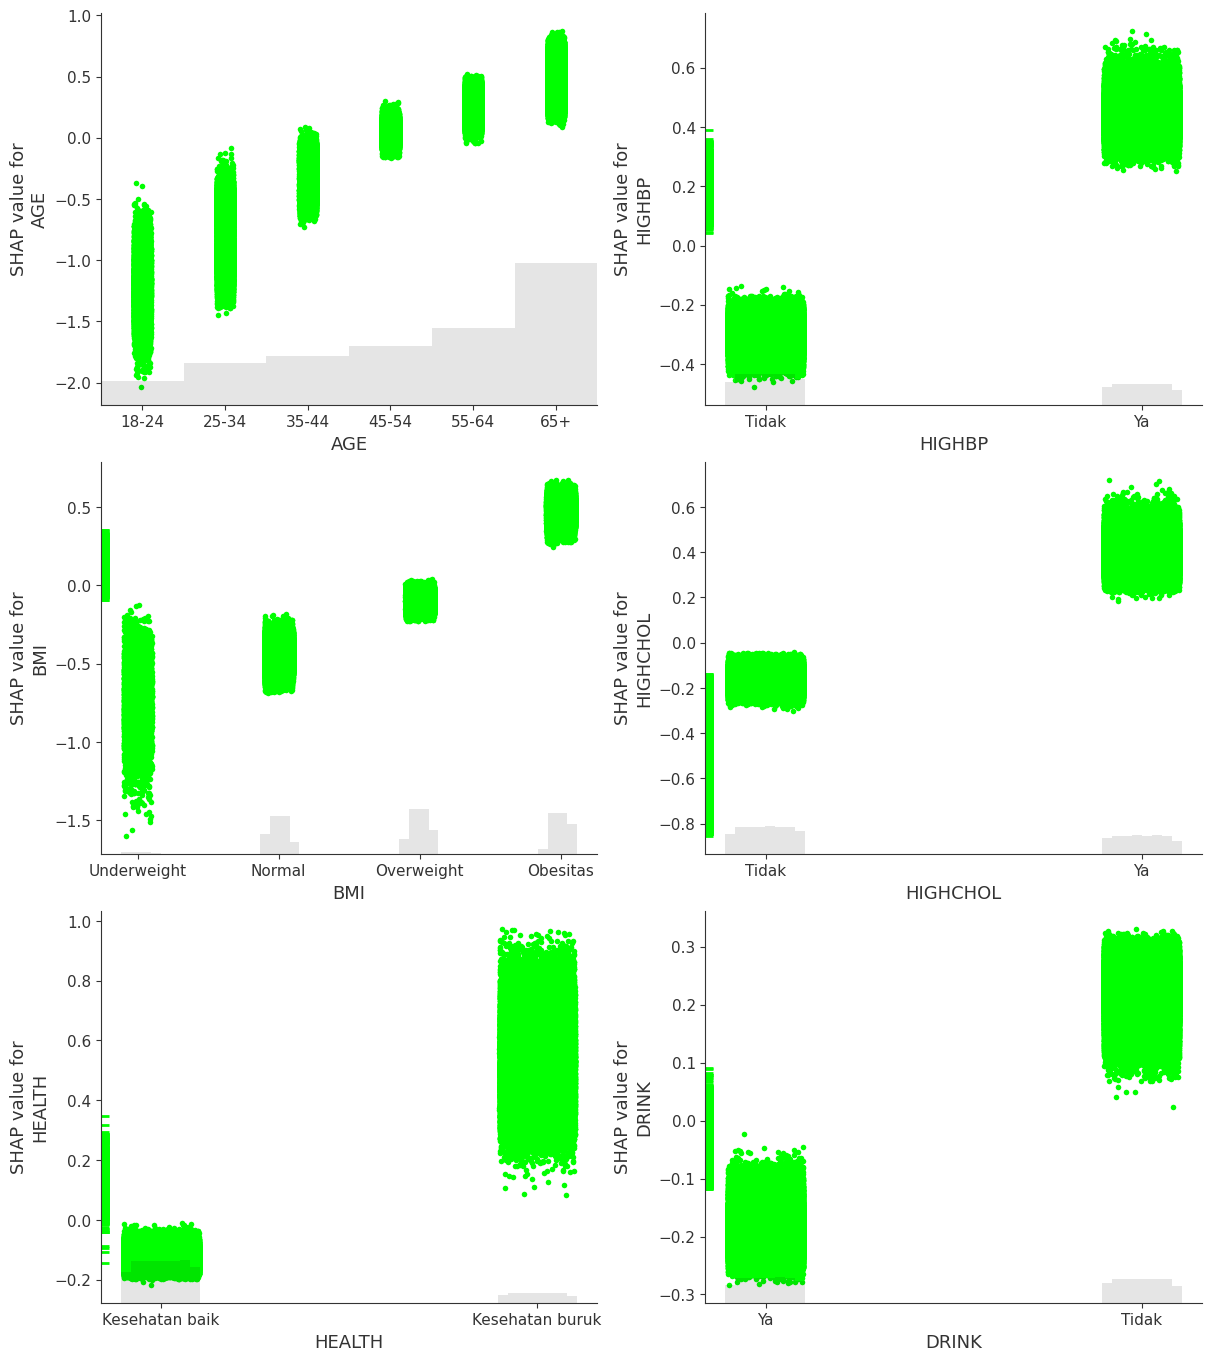

In [11]:
fig, axs = plt.subplots(nrows=3, 
                        ncols=2, 
                        sharex=False, 
                        sharey=False,
                        layout="constrained",
                        figsize=(12.0, 13.5)
                    )

age_ax = axs[0, 0]
highbp_ax = axs[0, 1]
bmi_ax = axs[1, 0]
highchol_ax = axs[1, 1]
health_ax = axs[2, 0]
drink_ax = axs[2, 1]

shap.plots.scatter(
    explanation[:, "AGE"],
    ax=age_ax,
    show=False,
    color='lime',
)

shap.plots.scatter(
    explanation[:, "HIGHBP"],
    ax=highbp_ax,
    show=False,
    color='lime',
)

shap.plots.scatter(
    explanation[:, "BMI"],
    ax=bmi_ax,
    show=False,
    color='lime',
)

shap.plots.scatter(
    explanation[:, "HIGHCHOL"],
    ax=highchol_ax,
    show=False,
    color='lime',
)

shap.plots.scatter(
    explanation[:, "HEALTH"],
    ax=health_ax,
    show=False,
    color='lime',
)

shap.plots.scatter(
    explanation[:, "DRINK"],
    ax=drink_ax,
    show=False,
    color='lime',
)

age_ax.set_xticks([0, 1, 2, 3, 4, 5])
age_ax.set_xticklabels(["18-24", "25-34", "35-44", "45-54", "55-64", "65+"])

highbp_ax.set_xticks([0.0, 1.0])
highbp_ax.set_xticklabels(["Tidak", "Ya"])

bmi_ax.set_xticks([0.0, 1.0, 2.0, 3.0])
bmi_ax.set_xticklabels(["Underweight", "Normal", "Overweight", "Obesitas"])

highchol_ax.set_xticks([0.0, 1.0])
highchol_ax.set_xticklabels(["Tidak", "Ya"])

health_ax.set_xticks([0.0, 1.0])
health_ax.set_xticklabels(["Kesehatan baik", "Kesehatan buruk"])

drink_ax.set_xticks([0.0, 1.0])
drink_ax.set_xticklabels(["Ya", "Tidak"])

plt.show()

In [12]:
replace_missing_explanation = shap.Explanation(
    values=sv,
    base_values=expv,
    data=X_test_replace_missing,
    feature_names=X_train.columns,
)

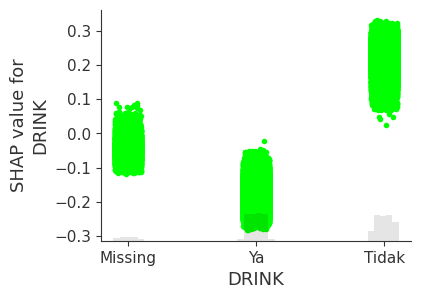

In [13]:
_, axt = plt.subplots(figsize=(4, 3))

shap.plots.scatter(
    replace_missing_explanation[:, "DRINK"],
    ax=axt,
    show=False,
    color='lime',
    hist=True,
)

axt.set_xticks([-1, 0.0, 1.0])
axt.set_xticklabels(["Missing", "Ya", "Tidak"])
plt.show()

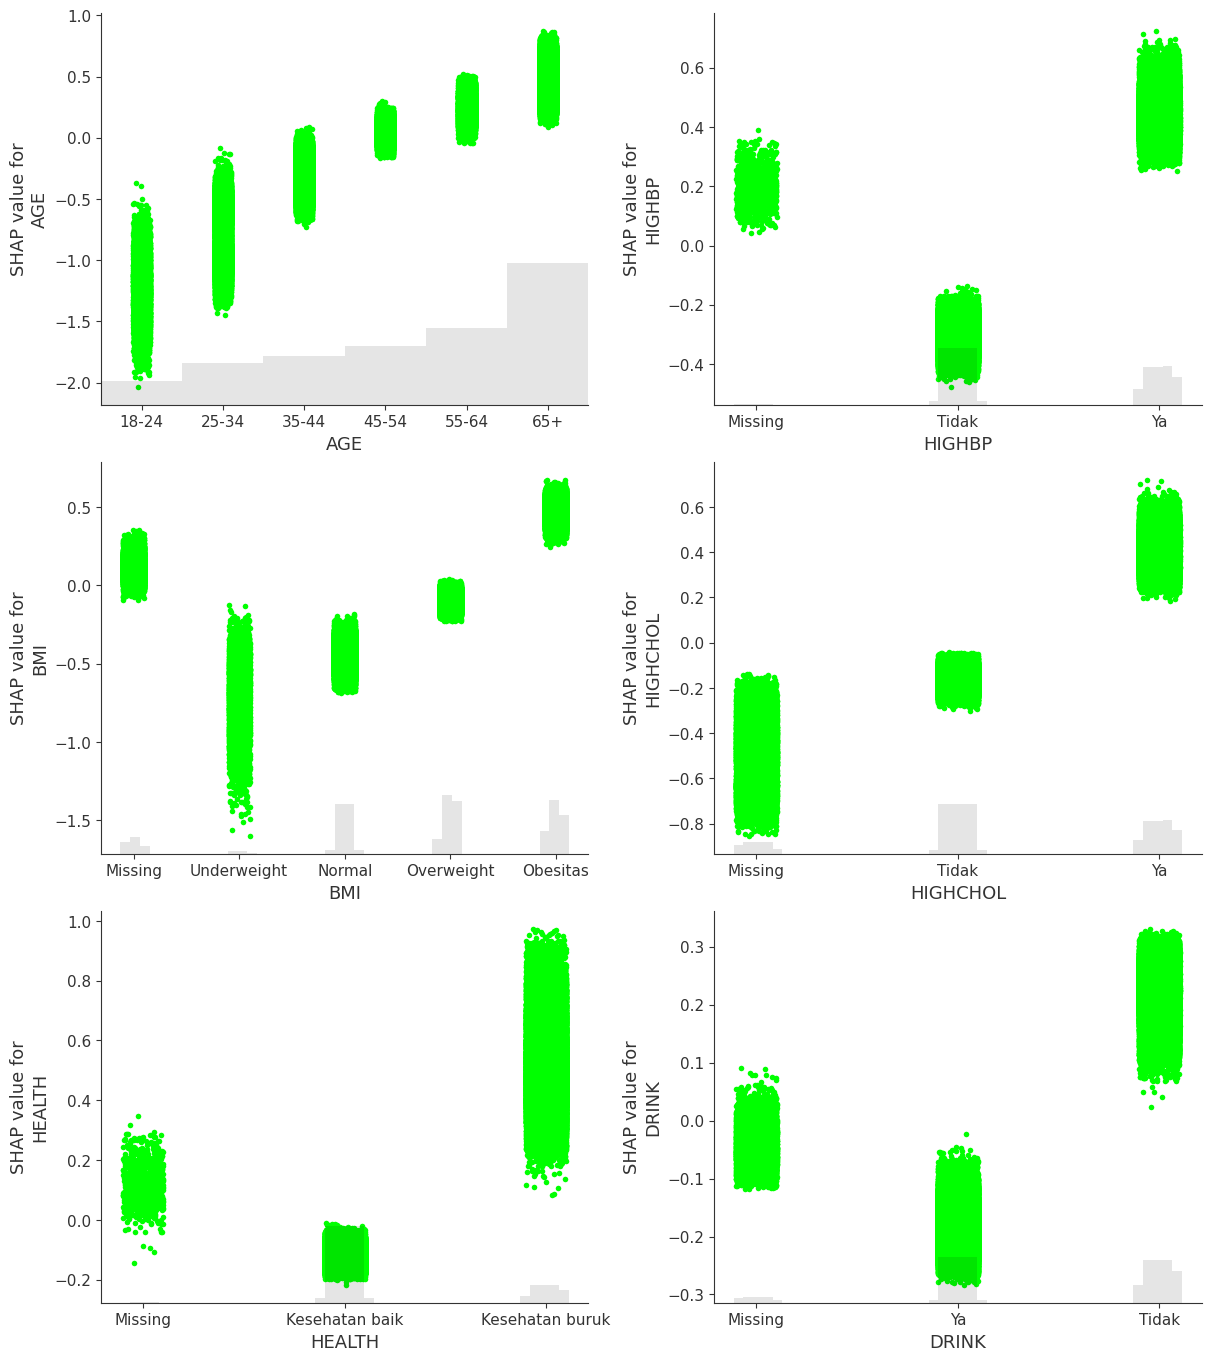

In [14]:
fig, axs = plt.subplots(nrows=3, 
                        ncols=2, 
                        sharex=False, 
                        sharey=False,
                        layout="constrained",
                        figsize=(12.0, 13.5)
                    )

age_ax = axs[0, 0]
highbp_ax = axs[0, 1]
bmi_ax = axs[1, 0]
highchol_ax = axs[1, 1]
health_ax = axs[2, 0]
drink_ax = axs[2, 1]

shap.plots.scatter(
    replace_missing_explanation[:, "AGE"],
    ax=age_ax,
    show=False,
    color='lime',
)

shap.plots.scatter(
    replace_missing_explanation[:, "HIGHBP"],
    ax=highbp_ax,
    show=False,
    color='lime',
)

shap.plots.scatter(
    replace_missing_explanation[:, "BMI"],
    ax=bmi_ax,
    show=False,
    color='lime',
)

shap.plots.scatter(
    replace_missing_explanation[:, "HIGHCHOL"],
    ax=highchol_ax,
    show=False,
    color='lime',
)

shap.plots.scatter(
    replace_missing_explanation[:, "HEALTH"],
    ax=health_ax,
    show=False,
    color='lime',
)

shap.plots.scatter(
    replace_missing_explanation[:, "DRINK"],
    ax=drink_ax,
    show=False,
    color='lime',
)

age_ax.set_xticks([0, 1, 2, 3, 4, 5])
age_ax.set_xticklabels(["18-24", "25-34", "35-44", "45-54", "55-64", "65+"])

highbp_ax.set_xticks([-1, 0.0, 1.0])
highbp_ax.set_xticklabels(["Missing", "Tidak", "Ya"])

bmi_ax.set_xticks([-1, 0.0, 1.0, 2.0, 3.0])
bmi_ax.set_xticklabels(["Missing", "Underweight", "Normal", "Overweight", "Obesitas"])

highchol_ax.set_xticks([-1, 0.0, 1.0])
highchol_ax.set_xticklabels(["Missing", "Tidak", "Ya"])

health_ax.set_xticks([-1, 0.0, 1.0])
health_ax.set_xticklabels(["Missing", "Kesehatan baik", "Kesehatan buruk"])

drink_ax.set_xticks([-1, 0.0, 1.0])
drink_ax.set_xticklabels(["Missing", "Ya", "Tidak"])

plt.show()

In [15]:
top_6_features = np.argsort(explanation.abs.mean(0).values)[::-1][:6]
top_6_features

array([10,  6, 15,  7, 16,  8])

In [16]:
explanation2 = shap.Explanation(
    values=sv[:, top_6_features],
    base_values=expv,
    data=X_test_np,
    feature_names=X_train.columns[top_6_features],
)

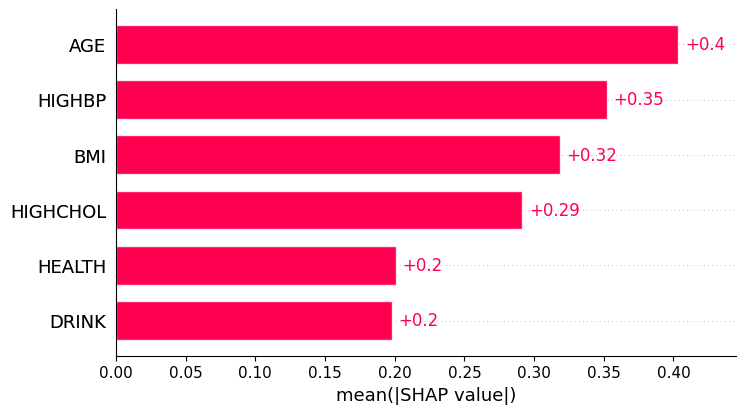

In [17]:
shap.plots.bar(explanation2)

In [18]:
# shap.plots.bar(explanation, max_display=33)

In [19]:
pred_proba1[:, 1]

array([0.03639171, 0.1060966 , 0.6068213 , ..., 0.30891612, 0.05217765,
       0.52660114], shape=(347338,), dtype=float32)

In [20]:
new_index = [i for i in range(len(X_test))]
X_test = X_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

In [21]:
X_test.reset_index(drop=True)

,SEX,INCOME,ARTHRITIS,EMPHYSEMA,DEPRESSION,KIDNEY,HIGHBP,HIGHCHOL,DRINK,INSURANCE,...,DIFFWALK,DIFFDRES,DIFFALON,HEART,STROKE,ASTHMA,SMOKER,EXERCISE,VETERAN,CANCER_DIAGNOSIS
0,0,2,1,1,1,1,0,NaN,1,0,...,1,1,1,1,1,0,3,0,1,0
1,0,4,1,1,1,1,0,0,0,1,...,1,1,1,1,1,0,3,0,1,0
2,1,4,0,1,1,1,1,1,0,NaN,...,0,1,1,1,1,0,3,0,1,1
3,1,NaN,1,1,1,0,0,NaN,1,0,...,1,1,1,1,1,NaN,3,0,1,0
4,1,4,1,1,1,1,0,0,0,0,...,1,1,1,1,1,0,3,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347333,1,3,1,1,1,1,1,1,0,NaN,...,1,1,1,1,1,0,3,0,1,1
347334,1,0,0,1,0,1,1,1,1,NaN,...,0,0,1,1,1,0,2,1,1,0
347335,0,4,0,1,1,1,0,0,0,NaN,...,1,1,1,1,1,0,2,0,0,1
347336,0,4,1,1,1,1,0,0,0,0,...,1,1,1,1,1,0,3,0,1,0


In [22]:
# True positive high confidence
tp = X_test[(y_test == 1) & (y_pred == 1) & (pred_proba1[:, 1] >= 0.9)].sample(1)

# True negative high confidence  
tn = X_test[(y_test == 0) & (y_pred == 0) & (pred_proba1[:, 1] <= 0.1)].sample(1)

# False negative
fn = X_test[(y_test == 1) & (y_pred == 0)].sample(1)

# Optional false positive
fp = X_test[(y_test == 0) & (y_pred == 1)].sample(1)

** True Positive **

In [23]:
tp.T

,236480
SEX,1
INCOME,0
ARTHRITIS,1
EMPHYSEMA,1
DEPRESSION,1
KIDNEY,1
HIGHBP,1
HIGHCHOL,1
DRINK,1
INSURANCE,0


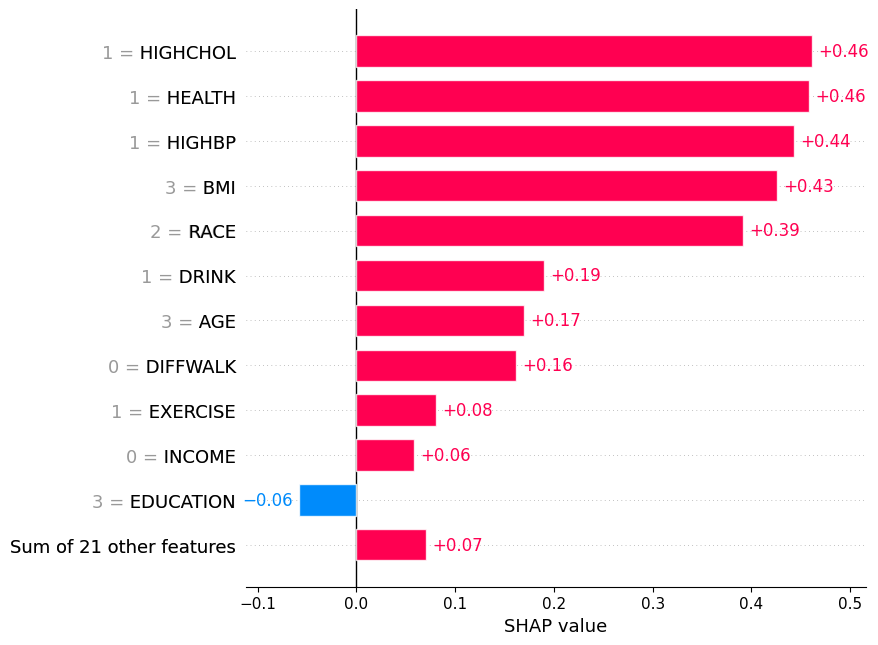

In [24]:
shap.plots.bar(explanation[tp.iloc[0].name], max_display=12)

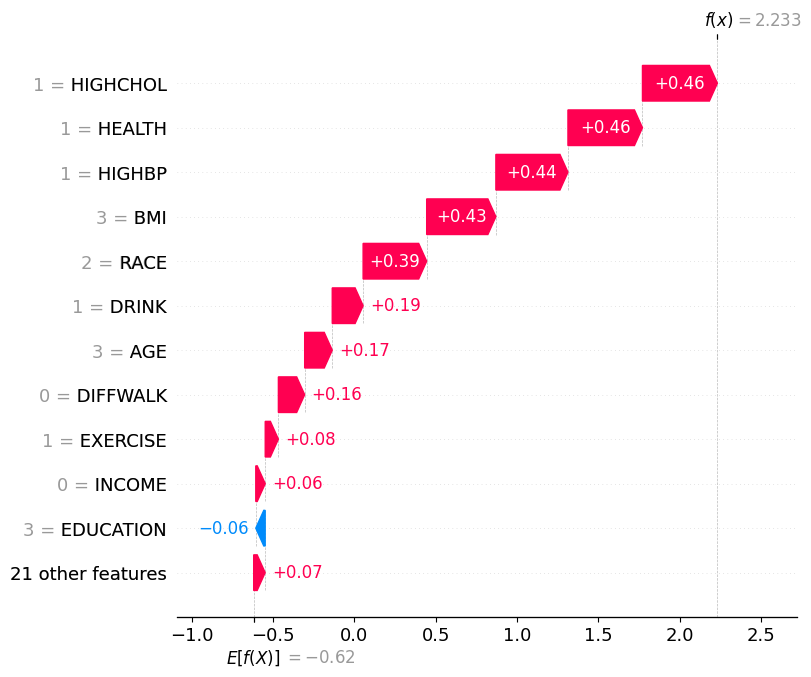

In [25]:
shap.plots.waterfall(explanation[tp.iloc[0].name], max_display=12)

** True Negative **

In [26]:
tn.T

,335338
SEX,0
INCOME,2
ARTHRITIS,1
EMPHYSEMA,1
DEPRESSION,0
KIDNEY,1
HIGHBP,0
HIGHCHOL,NaN
DRINK,1
INSURANCE,0


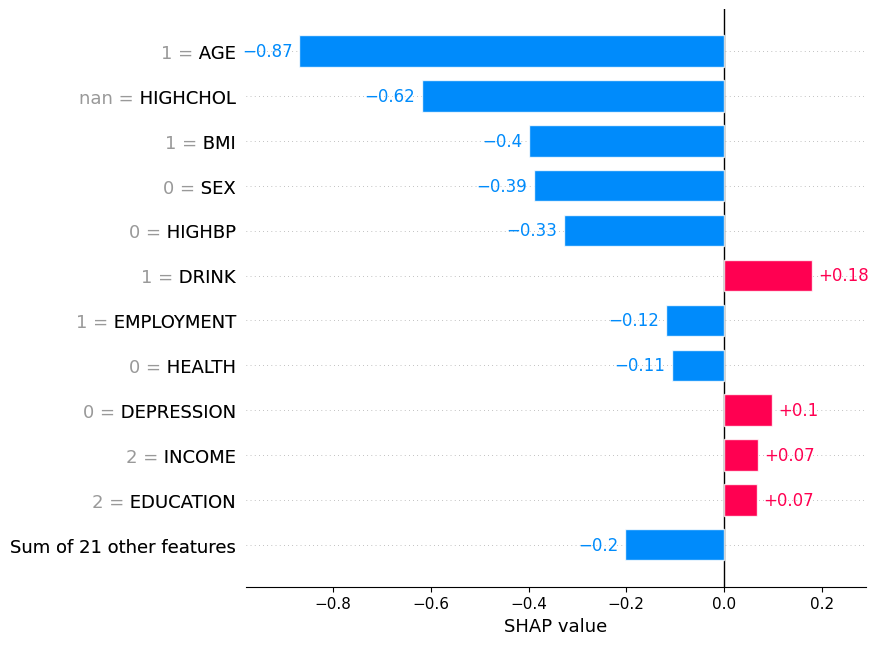

In [27]:
shap.plots.bar(explanation[tn.iloc[0].name], max_display=12)

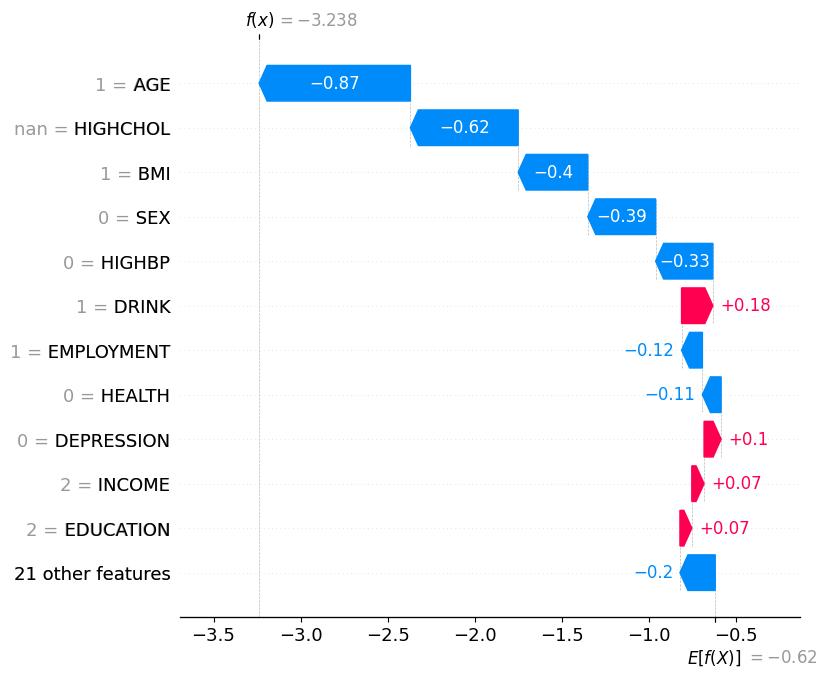

In [28]:
shap.plots.waterfall(explanation[tn.iloc[0].name], max_display=12)

** False Negative **

In [29]:
fn.T

,43199
SEX,1
INCOME,NaN
ARTHRITIS,1
EMPHYSEMA,1
DEPRESSION,1
KIDNEY,1
HIGHBP,0
HIGHCHOL,0
DRINK,NaN
INSURANCE,0


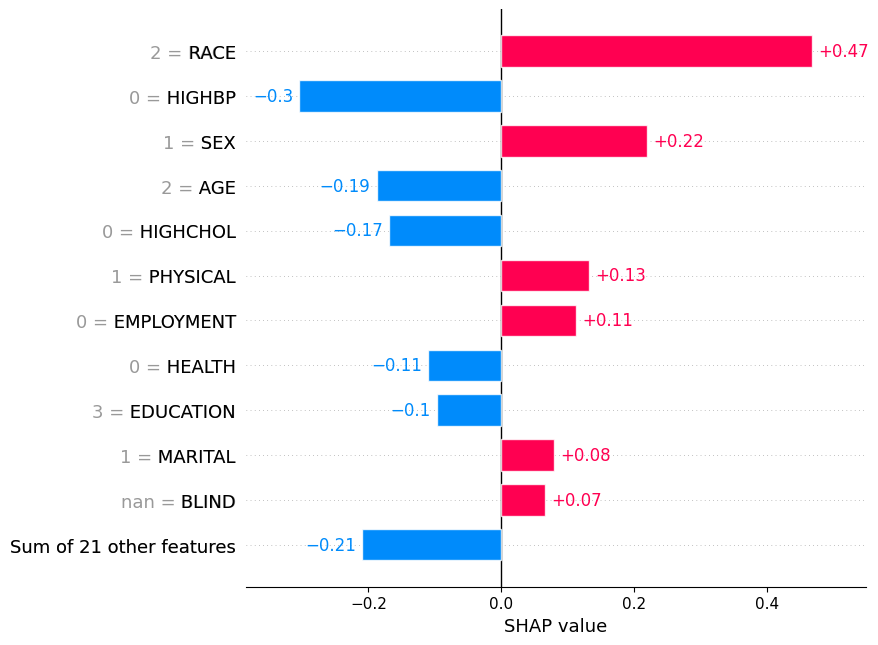

In [30]:
shap.plots.bar(explanation[fn.iloc[0].name], max_display=12)

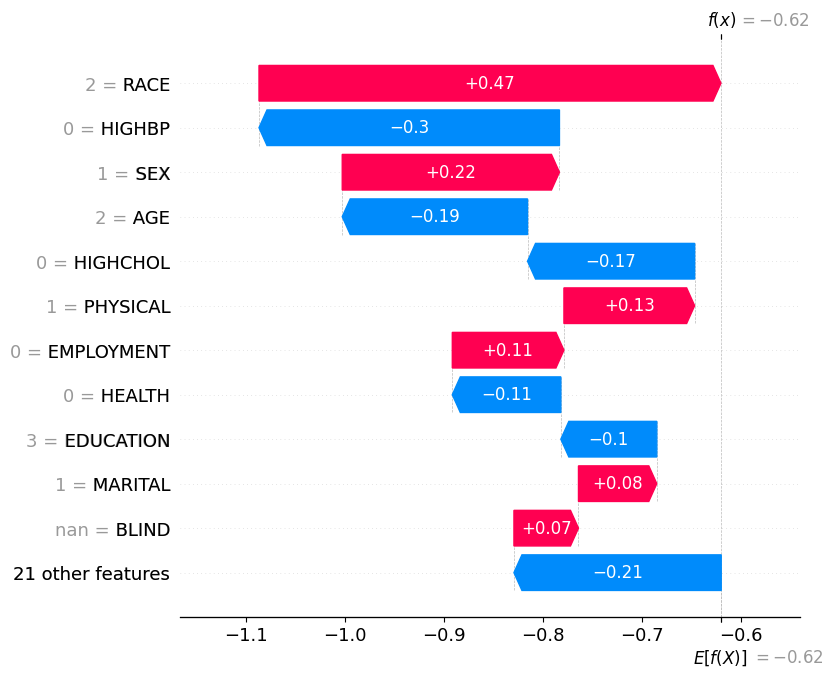

In [31]:
shap.plots.waterfall(explanation[fn.iloc[0].name], max_display=12)

** False Positive **

In [32]:
fp.T

,241154
SEX,1
INCOME,4
ARTHRITIS,1
EMPHYSEMA,1
DEPRESSION,0
KIDNEY,1
HIGHBP,0
HIGHCHOL,1
DRINK,1
INSURANCE,0


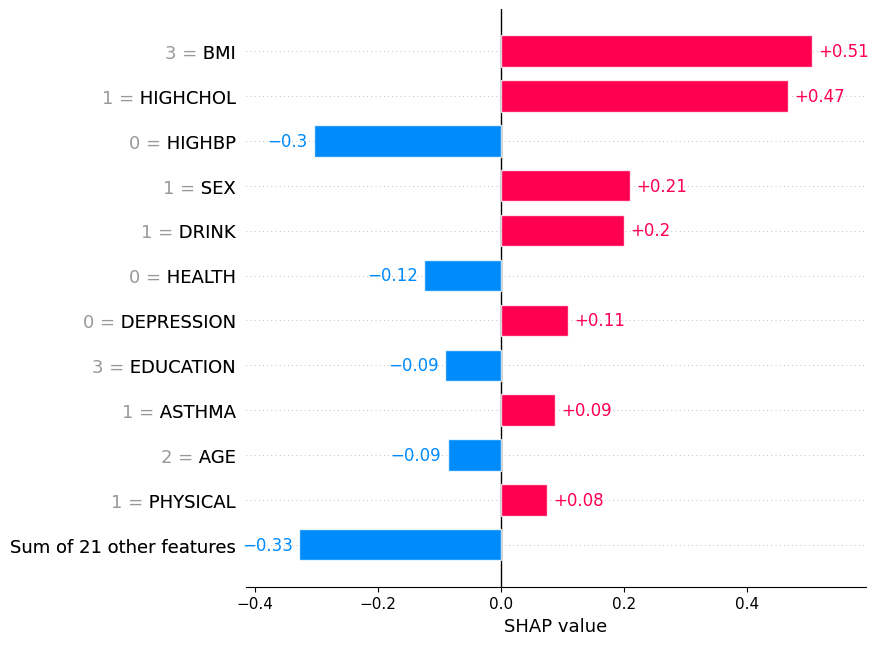

In [33]:
shap.plots.bar(explanation[fp.iloc[0].name], max_display=12)

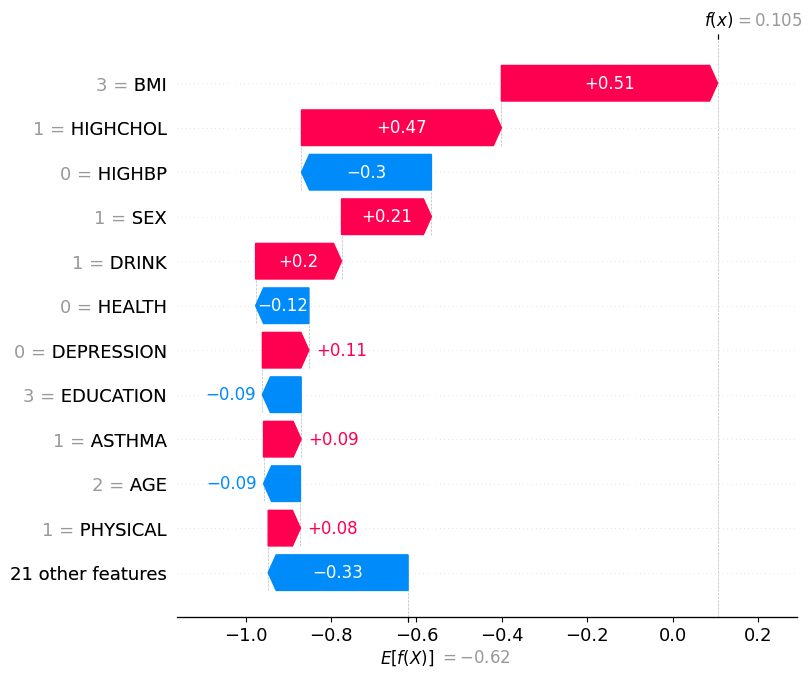

In [34]:
shap.plots.waterfall(explanation[fp.iloc[0].name], max_display=12)